# TWPA system noise from the qubit-calibrated gain (5.576 GHz)

System noise temperature $T_\mathrm{sys}$ of the readout chain with the TWPA pump **off** and **on**. The absolute
gain comes from the qubit power calibration (`2_qubit_power_fit`). Each SA spectrum holds a calibration tone
(gain) and the noise floor (noise).

**Measurement (2026-10-16)**: SynthHD probe −25 dBm at 5.576 GHz, RCDAT 25 dB, into the fridge input line
(qubit → TWPA → HEMT → warm amplifiers) and out to the E7405A. SA: span 500 kHz around 5.57597 GHz,
**RBW 10 kHz, VBW 100 Hz**, sample detector, LOG, **ref level −40 dBm**, input attenuation 0 dB, 401 points,
50-trace live-view average (power average, `labserver/averaging.py`). TWPA pump: SynthHD 8.52 GHz, 7 dBm, off / on.
Noise source and qubit flux bias outputs off. SA filters aligned (Align Now, All) before the measurement.

| file | pump | what it gives |
|---|---|---|
| `SA_pump_off.json` | off | tone → reference level; floor → $T_\mathrm{sys,off}$ |
| `SA_pump_on.json` | on (8.52 GHz, 7 dBm) | tone → TWPA on/off gain $\Delta G$; floor → $T_\mathrm{sys,on}$ |

Parameters from other measurements (entered by hand below):

| quantity | value | source |
|---|---|---|
| input line attenuation $A_\mathrm{in}$ (VNA port → qubit, incl. RCDAT 25 dB) | 102.36 dB | `2_qubit_power_fit/3-level-fit`, qubit power fit (3-level, Fano) |
| $S_{21}$ at 5.576 GHz, TWPA off | −48.644 dB | VNA CW, −20 dBm, IFBW 10 Hz, 10 averages (`2_qubit_power_fit/5_576ghz_vna_cw_-20dbm.json`) |
| $G_\mathrm{off} = S_{21} + A_\mathrm{in}$ | 53.72 dB | qubit plane → SA |
| LOG-scale noise correction | +2.51 dB | AN 1303; `3_yfactor/yfactor_fit.ipynb` |
| loss qubit → TWPA, TWPA internal loss | 0 dB (optional inputs) | see *Losses* below |

## Theory

**Reference plane and gain.** The qubit power fit gives the input-line attenuation $A_\mathrm{in}$ (VNA port →
qubit), and the VNA through measurement is $S_{21} = -A_\mathrm{in} + G$ (dB), so the output-chain gain from the
qubit to the SA with the TWPA off is

$$G_\mathrm{off} = S_{21,\mathrm{off}} + A_\mathrm{in}.$$

**TWPA on/off gain.** The probe tone has the same power at the qubit in both spectra (same SynthHD level, same
RCDAT, same switches), so the ratio of the two tone readings is the on/off gain, and $A_\mathrm{in}$, the SynthHD
level and the warm input path all cancel:

$$\Delta G = \frac{P_\mathrm{tone,on}}{P_\mathrm{tone,off}}, \qquad G_\mathrm{on} = G_\mathrm{off}\,\Delta G.$$

**System noise temperature.** The SA floor in one RBW is white noise through the RBW filter,

$$P_N = G\,k_B T_\mathrm{sys}\,B_N \quad\Rightarrow\quad
T_\mathrm{sys} = \frac{P_{N,\mathrm{read}}\cdot 10^{c/10}}{k_B\,B_N\,G},$$

with $c = 2.51$ dB the LOG-scale under-reading of Gaussian noise and $B_N$ the equivalent noise bandwidth of the
RBW filter. With VBW/RBW = 0.01 the video filter averages the log-detected noise fully, and for the exponential
power distribution of narrowband noise $\langle 10\log_{10}x\rangle = 10\log_{10}\langle x\rangle - 10\gamma/\ln 10$
($\gamma$ = Euler's constant), i.e. 2.51 dB. A tone at the filter peak reads its full power at any RBW, so the gain
has no bandwidth in it; the noise does, and $B_N$ links the two. $T_\mathrm{sys}$ defined this way includes the
noise of the mode entering the reference plane (vacuum at 20 mK) and everything after it, the SA included.

**ENBW of RBW 10 kHz.** Measured from the tone in the same spectra. The video filter ($\tau = 1/2\pi\,\mathrm{VBW}$
= 1.6 ms) acts on the log signal while the SA sweeps 500 kHz in 0.64 s, so it smears the trace by
span·τ/sweep time ≈ 1.2 kHz (12 % of the RBW) towards higher frequency. That lowers the tone peak by ~0.4 dB
without touching the flat floor. It cancels in $\Delta G$ (same shape in both spectra) and biases the plain
area/peak ENBW high. $B_N$ comes from a fit of a 4-pole synchronously tuned filter $[1+(f/a)^2]^{-4}$ (AN 1303)
passed through the one-pole video filter: $B_N = (5\pi/16)\,a = 1.128\,B_{3\,\mathrm{dB}}$.

**Quantum limit.** In photons, $n_\mathrm{sys} = k_B T_\mathrm{sys}/hf$ ($hf/k_B$ = 0.268 K at 5.576 GHz). The
input mode carries $n_\mathrm{in} = \tfrac12\coth(hf/2k_BT) \approx \tfrac12$, and a phase-preserving amplifier
adds at least $\tfrac12$ (Caves 1982), so $n_\mathrm{sys} \ge 1$ (SQL, $T = hf/k_B$) and the system added noise
$n_\mathrm{add} = n_\mathrm{sys} - n_\mathrm{in} \ge \tfrac12$. The quantum efficiency at the qubit is
$\eta = 1/(2n_\mathrm{sys})$: ½ at the phase-preserving limit, 1 for an ideal phase-sensitive measurement.

**Losses (optional, default 0 dB).** Two passive losses can be entered, both at physical temperature $T_L$:
$L_1$ between the qubit and the TWPA input (cables, connectors, isolators), and $L_T$ inside the TWPA (its
pump-off insertion loss), lumped at the TWPA input. With transmissions $\alpha_1 = 10^{-L_1/10}$ and
$\alpha_T = 10^{-L_T/10}$ this defines three reference planes:

| plane | gain to the SA | $T_\mathrm{sys}$ | input mode |
|---|---|---|---|
| qubit | $G$ | $T_\mathrm{sys,q}$ | $n_\mathrm{in,q}$ |
| TWPA input | $G/\alpha_1$ | $\alpha_1 T_\mathrm{sys,q}$ | $\alpha_1 n_\mathrm{in,q} + (1-\alpha_1)\,n_\mathrm{th}(T_L)$ |
| TWPA gain medium | $G/\alpha_1\alpha_T$ | $\alpha_1\alpha_T T_\mathrm{sys,q}$ | $\alpha_T n_\mathrm{in,t} + (1-\alpha_T)\,n_\mathrm{th}(T_L)$ |

The output noise is the same; only the gain it is divided by changes, so moving the plane past a loss scales
$T_\mathrm{sys}$ by the transmission. A cold loss feeds in its own $n_\mathrm{th}(T_L) \approx \tfrac12$, so
the input mode stays at ½ and $n_\mathrm{add}$ at the later plane is smaller: the loss's share of the noise moves
out of $n_\mathrm{add}$. The net TWPA gain is $\Delta G\cdot\alpha_T$ (on/off gain minus insertion loss).

**Friis split.** With $L_T$ lumped at the input, the gain medium is transparent with the pump off and has gain
$\Delta G$ with the pump on, and the chain after it is the same in both states. At the gain-medium plane

$$n_\mathrm{sys,on} = n_\mathrm{in} + n_\mathrm{TWPA} + \frac{n_\mathrm{sys,off} - n_\mathrm{in}}{\Delta G},$$

which separates the TWPA's intrinsic added noise $n_\mathrm{TWPA}$ from what the HEMT chain still contributes.
This is Eq. (G.6) of Sandbo Chang *et al.* For a phase-preserving amplifier of gain $G$ the limit is
$n_\mathrm{TWPA} \ge \tfrac12(1 - 1/G)$ (Caves 1982), ≈ ½ at high gain. Lumping all of $L_T$ at the input is the
conservative choice; entering half the insertion loss puts the plane at the middle of the TWPA, as Sandbo Chang
*et al.* do (half the loss at the input and half at the output). For a loss distributed along the line the
intrinsic added noise lies between the values with $L_T$ = 0 and $L_T$ = the full insertion loss.

**Uncertainty.** The systematic uncertainties of the system gain $G_\mathrm{off}$ (qubit fit, $S_{21}$, receiver
path), the on/off gain $\Delta G$ and the two losses are entered as ± dB. Every result is evaluated at all
combinations of (−u, 0, +u) of the four inputs (a loss is never taken below 0 dB), and the range is the minimum
to the maximum over them. Sandbo Chang *et al.* use ±0.5 dB on the system gain in the same way.

**References**
- T. Hönigl-Decrinis *et al.*, PRApplied 13, 024066 (2020),
  [doi:10.1103/PhysRevApplied.13.024066](https://doi.org/10.1103/PhysRevApplied.13.024066).
  Waveguide-qubit power sweep → absolute input attenuation (used in `2_qubit_power_fit`).
- C. W. Sandbo Chang *et al.*, *Josephson traveling-wave parametric amplifier based on low-intrinsic-loss coplanar
  lumped-element waveguide*, [arXiv:2503.07559](https://arxiv.org/abs/2503.07559). App. G: qubit-based system
  calibration (Eq. G.1, used in `qubit_power_fit_fano.ipynb`), package losses split half/half around the JTWPA
  (Eq. G.2), JTWPA added noise from pump on/off noise (Eqs. G.3–G.6), ±0.5 dB systematic envelope on the gain.
- C. M. Caves, *Quantum limits on noise in linear amplifiers*, Phys. Rev. D 26, 1817 (1982),
  [doi:10.1103/PhysRevD.26.1817](https://doi.org/10.1103/PhysRevD.26.1817). Phase-preserving amplifiers add
  at least half a photon.
- A. A. Clerk *et al.*, *Introduction to quantum noise, measurement, and amplification*, Rev. Mod. Phys. 82, 1155
  (2010), [doi:10.1103/RevModPhys.82.1155](https://doi.org/10.1103/RevModPhys.82.1155). Added noise, noise
  temperature in photons, the quantum limit; beam-splitter model of a cold loss.
- C. Macklin *et al.*, *A near–quantum-limited Josephson traveling-wave parametric amplifier*, Science 350, 307
  (2015), [doi:10.1126/science.aaa8525](https://doi.org/10.1126/science.aaa8525). JTWPA gain and noise
  characterization.
- H. T. Friis, *Noise figures of radio receivers*, Proc. IRE 32, 419 (1944),
  [doi:10.1109/JRPROC.1944.232049](https://doi.org/10.1109/JRPROC.1944.232049). Cascaded noise temperature.
- Agilent AN 1303, *Spectrum Analyzer Measurements and Noise* (5966-4008E):
  [PDF copy](https://rose-hulman.edu/class/ee/voltmer/My%20DocumentsB/wireless/spec_analyz.pdf).
  Log under-response 2.51 dB (p. 8), 4-pole RBW filters and ENBW = 1.128 × B3dB (pp. 8–9).
- Keysight AN 150, *Spectrum Analysis Basics* (5952-0292):
  [PDF copy](https://xdevs.com/doc/HP_Agilent_Keysight/5952-0292%20English%20_%202014-02-25%20_%20PDF%205.71%20MB%20c20141003%20%5B89%5D.pdf).
  Video filtering and sweep time, noise in log mode (pp. 53–54).
- Keysight AN 57-1, *Fundamentals of RF and Microwave Noise Figure Measurements* (5952-8255E). Noise temperature
  and the Friis formula.

In [1]:
import json
import os
from math import pi, sqrt
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.signal import lfilter, lfilter_zi

kB = 1.380649e-23
h = 6.62607015e-34

## Parameters
Everything here was measured or calibrated elsewhere; edit before running.

In [19]:
FILE_OFF = "SA_pump_off.json"
FILE_ON = "SA_pump_on_8_53ghz_6_5dbm.json"

# gain, qubit plane -> SA, TWPA off (Summary_Note.md)
A_IN_DB = 102.36 - 25      # VNA port -> qubit incl. RCDAT 25 dB, 3-level qubit power fit at f0 = 5.576 GHz         # data is from RCDAT 0 dB. so subtracted 25 dB
S21_OFF_DB = -48.644 + 25       # VNA CW 5.576 GHz, -20 dBm, 101 points, IFBW 10 Hz, 10 averages, TWPA off          # attenuation is lower, S21 should be higher
G_OFF_DB = S21_OFF_DB + A_IN_DB   # 53.72 dB

# SA noise reading
LOG_VBW_CORR_DB = 2.51     # LOG scale + VBW << RBW reads noise low by 2.51 dB
TONE_EXCL_HZ = 100e3       # noise floor = points farther than this from the tone (RBW 10 kHz filter is < -70 dB there)
ENBW_HZ = None             # RBW 10 kHz ENBW; None -> smear-corrected 4-pole fit to the tone (below)

# optional losses, both 0 dB by default (then all three planes coincide)
LOSS_QUBIT_TWPA_DB = 0.0   # qubit -> TWPA input: cables, connectors, isolators
LOSS_TWPA_DB = 0.0         # TWPA internal loss, lumped at the TWPA input
                           # (full insertion loss: conservative; half of it: plane at the TWPA middle, as Sandbo Chang et al.)
T_LOSS_K = 0.020           # physical temperature of both losses
T_IN_K = 0.020             # temperature of the mode entering the qubit plane (mixing chamber)
PLOT_PLANE = "qubit"       # plane of the noise spectra figure: "qubit", "twpa" or "amp" (TWPA gain medium)

# systematic uncertainties, ± dB; results are given as ranges over all combinations
G_OFF_UNC_DB = 0.5         # system gain G_off (qubit fit, S21, receiver path); 0.5 dB as Sandbo Chang et al.
DG_UNC_DB = 0.0            # TWPA on/off gain
LOSS_QUBIT_TWPA_UNC_DB = 0.0
LOSS_TWPA_UNC_DB = 0.0

## Load the spectra

In [20]:
def load(fn):
    with open(fn) as fh:
        d = json.load(fh)
    t = d["trace"]
    return d, np.array(t["x"]), np.array(t["y"])

d_off, f_off, y_off = load(FILE_OFF)
d_on, f_on, y_on = load(FILE_ON)

for name, d in (("off", d_off), ("on", d_on)):
    t, sa, syn, sw = (d["trace"], d["instruments"]["spa"], d["instruments"]["rf_synth"],
                      d["instruments"]["warm_switches"])
    print(f"pump {name}: {d['date']} {d['time']}  span {t['span_hz']/1e3:g} kHz, RBW {t['rbw_hz']/1e3:g} kHz, "
          f"VBW {t['vbw_hz']:g} Hz, {sa['detector']}, {t['scale']}, {t['averages']} averages, "
          f"sweep {sa['sweep_time_s']*1e3:.0f} ms, ref {sa['ref_level']:g} dBm, atten {sa['attenuation_db']:g} dB")
    print(f"          probe {syn['probe_frequency_hz']/1e9:g} GHz {syn['probe_power_dbm']:g} dBm, "
          f"RCDAT {d['instruments']['attenuator']['attenuation_db']:g} dB, "
          f"pump {'ON' if syn['pump_enable'] else 'off'} ({syn['pump_frequency_hz']/1e9:g} GHz, "
          f"{syn['pump_power_dbm']:g} dBm), {sw['fridge_in']} -> fridge -> {sw['receiver']}")

# the method needs the same tone and the same SA settings in both spectra, and only the pump changed
keys_sa = ("center_hz", "span_hz", "rbw_hz", "vbw_hz", "detector", "scale", "ref_level", "sweep_time_s", "attenuation_db")
keys_syn = ("probe_enable", "probe_frequency_hz", "probe_power_dbm")
for k in keys_sa:
    if d_off["instruments"]["spa"][k] != d_on["instruments"]["spa"][k]:
        print(f"WARNING: SA {k} differs between the spectra")
for k in keys_syn:
    if d_off["instruments"]["rf_synth"][k] != d_on["instruments"]["rf_synth"][k]:
        print(f"WARNING: probe {k} differs between the spectra")
if d_off["instruments"]["attenuator"] != d_on["instruments"]["attenuator"]:
    print("WARNING: RCDAT setting differs")
if d_off["instruments"]["rf_synth"]["pump_enable"] or not d_on["instruments"]["rf_synth"]["pump_enable"]:
    print("WARNING: pump state is not off / on as the file names say")
if d_on["trace"]["vbw_hz"] / d_on["trace"]["rbw_hz"] > 0.03:
    print("WARNING: VBW is not << RBW; the 2.51 dB log correction does not apply")

pump off: 16-10-2026 14:12:30  span 500 kHz, RBW 10 kHz, VBW 100 Hz, SAMP, LOG, 50 averages, sweep 642 ms, ref -20 dBm, atten 0 dB
          probe 5.576 GHz -40 dBm, RCDAT 0 dB, pump off (8.52 GHz, 7 dBm), rf_probe -> fridge -> spa
pump on: 16-10-2026 14:30:08  span 500 kHz, RBW 10 kHz, VBW 100 Hz, SAMP, LOG, 50 averages, sweep 642 ms, ref -20 dBm, atten 0 dB
          probe 5.576 GHz -40 dBm, RCDAT 0 dB, pump ON (8.53 GHz, 6.5 dBm), rf_probe -> fridge -> spa


## Spectra
Both spectra on one axis, offset from the tone. The shaded band is excluded from the noise floor.

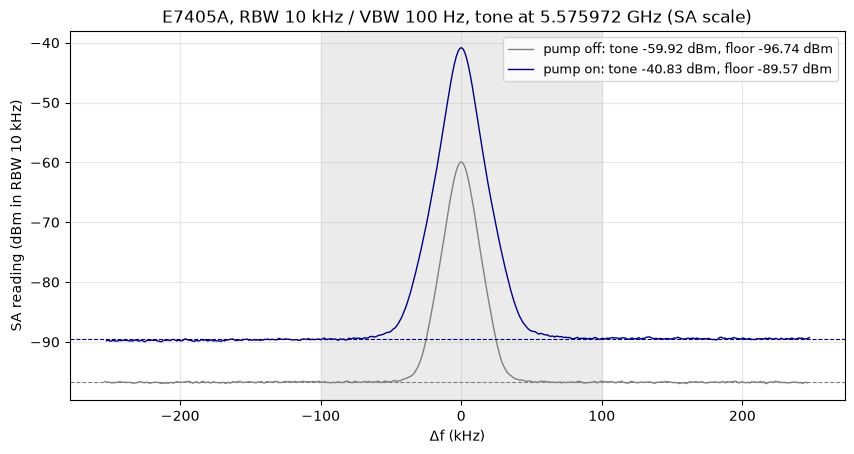

In [21]:
def analyse(f, y, rbw):
    P = 10 ** (y / 10) * 1e-3                       # W
    ip = np.argmax(y)
    c2, c1, c0 = np.polyfit(f[ip-3:ip+4] - f[ip], y[ip-3:ip+4], 2)   # parabola through the top 7 points (dB)
    f_pk = f[ip] - c1 / (2 * c2)
    y_pk = c0 - c1 ** 2 / (4 * c2)
    far = np.abs(f - f_pk) > TONE_EXCL_HZ
    floor_w = P[far].mean()                         # floor reading in one RBW (W), still 2.51 dB low
    # adjacent points are correlated (1.25 kHz step < RBW), so count independent samples as span / RBW
    n_ind = far.sum() * (f[1] - f[0]) / rbw
    floor_sem_db = 10 * np.log10(1 + P[far].std(ddof=1) / floor_w / sqrt(n_ind))
    tone_w = 10 ** (y_pk / 10) * 1e-3 - floor_w     # the tone reads correctly; remove the floor under it
    return dict(P=P, f_pk=f_pk, y_pk=y_pk, far=far, floor_w=floor_w, floor_sem_db=floor_sem_db, tone_w=tone_w)

r_off = analyse(f_off, y_off, d_off["trace"]["rbw_hz"])
r_on = analyse(f_on, y_on, d_on["trace"]["rbw_hz"])
dBm = lambda w: 10 * np.log10(w * 1e3)
dB = lambda x: 10 * np.log10(x)

fig, ax = plt.subplots(figsize=(10, 4.8))
for name, f, y, r, c in (("pump off", f_off, y_off, r_off, "0.5"), ("pump on", f_on, y_on, r_on, "navy")):
    ax.plot((f - r["f_pk"]) / 1e3, y, color=c, lw=1, label=f"{name}: tone {r['y_pk']:.2f} dBm, floor {dBm(r['floor_w']):.2f} dBm")
    ax.axhline(dBm(r["floor_w"]), color=c, ls="--", lw=0.8)
ax.axvspan(-TONE_EXCL_HZ / 1e3, TONE_EXCL_HZ / 1e3, color="0.92", zorder=0)
ax.set(xlabel="Δf (kHz)", ylabel="SA reading (dBm in RBW 10 kHz)",
       title=f"E7405A, RBW 10 kHz / VBW 100 Hz, tone at {r_on['f_pk']/1e9:.6f} GHz (SA scale)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right", fontsize=9)
plt.show()

## On/off gain and noise rise

In [22]:
dG = r_on["tone_w"] / r_off["tone_w"]
dN = r_on["floor_w"] / r_off["floor_w"]
dSNR = dG / dN

for name, r in (("off", r_off), ("on ", r_on)):
    print(f"pump {name}: tone {dBm(r['tone_w']):7.2f} dBm, floor {dBm(r['floor_w']):7.2f} dBm "
          f"(± {r['floor_sem_db']:.3f} dB stat., {r['far'].sum()} points), SNR in RBW {dB(r['tone_w']/r['floor_w']):.1f} dB")
print(f"\nTWPA on/off gain   ΔG   = {dB(dG):6.2f} dB")
print(f"noise rise         ΔN   = {dB(dN):6.2f} dB")
print(f"SNR improvement    ΔSNR = {dB(dSNR):6.2f} dB")
print(f"\nG_off = {G_OFF_DB:.2f} dB  ->  G_on = {G_OFF_DB + dB(dG):.2f} dB (qubit plane -> SA)")
print(f"probe at the qubit ≈ {dBm(r_off['tone_w']) - G_OFF_DB:.1f} dBm (tone_off − G_off; far below TWPA saturation)")

pump off: tone  -59.92 dBm, floor  -96.74 dBm (± 0.016 dB stat., 241 points), SNR in RBW 36.8 dB
pump on : tone  -40.83 dBm, floor  -89.57 dBm (± 0.031 dB stat., 241 points), SNR in RBW 48.7 dB

TWPA on/off gain   ΔG   =  19.09 dB
noise rise         ΔN   =   7.18 dB
SNR improvement    ΔSNR =  11.91 dB

G_off = 53.72 dB  ->  G_on = 72.80 dB (qubit plane -> SA)
probe at the qubit ≈ -113.6 dBm (tone_off − G_off; far below TWPA saturation)


## ENBW of the RBW 10 kHz filter
Area/peak of the floor-subtracted tone (biased high by the video smear) and the smear-corrected 4-pole fit
within ±40 kHz. The fit value is used; `ENBW_HZ` overrides it.

In [23]:
def swept_model(f, peak_dbm, f0, a, floor_w, smear_hz):
    # 4-pole RBW response to a CW tone plus the floor, in dBm, then the one-pole video filter along the sweep
    # (it acts on the log-detected signal and lags the sweep, i.e. smears towards higher f)
    step = (f[1] - f[0]) / 20
    ff = np.arange(f[0] - 20 * smear_hz, f[-1] + step, step)
    ydb = 10 * np.log10((10 ** (peak_dbm / 10) * 1e-3 * (1 + ((ff - f0) / a) ** 2) ** -4 + floor_w) * 1e3)
    alpha = np.exp(-step / smear_hz)
    b, a_ = [1 - alpha], [1, -alpha]
    out, _ = lfilter(b, a_, ydb, zi=lfilter_zi(b, a_) * ydb[0])
    return np.interp(f, ff, out)

def enbw_estimates(d, f, y, r):
    t, sa = d["trace"], d["instruments"]["spa"]
    smear = t["span_hz"] / sa["sweep_time_s"] / (2 * pi * t["vbw_hz"])
    s = (r["P"] - r["floor_w"]) / (10 ** (r["y_pk"] / 10) * 1e-3 - r["floor_w"])
    area = s[~r["far"]].sum() * (f[1] - f[0])
    m = np.abs(f - r["f_pk"]) < 40e3
    a0 = t["rbw_hz"] / (2 * sqrt(2 ** 0.25 - 1))
    fit = least_squares(lambda p: (swept_model(f, *p, r["floor_w"], smear) - y)[m],
                        [r["y_pk"] + 0.3, r["f_pk"] - smear, a0])
    pk, f0, a = fit.x
    return dict(smear=smear, area=area, fit=5 * pi / 16 * a, b3=2 * a * sqrt(2 ** 0.25 - 1),
                peak_true=pk, f0=f0, a=a, resid=np.sqrt(np.mean(fit.fun ** 2)))

e_off = enbw_estimates(d_off, f_off, y_off, r_off)
e_on = enbw_estimates(d_on, f_on, y_on, r_on)

print(f"video smear length {e_on['smear']:.0f} Hz")
for name, e, r in (("off", e_off, r_off), ("on ", e_on, r_on)):
    print(f"pump {name}: area/peak {e['area']:7.0f} Hz | fit: B3 {e['b3']:6.0f} Hz, ENBW {e['fit']:6.0f} Hz, "
          f"peak {e['peak_true']:.2f} dBm (read {r['y_pk']:.2f}), rms resid {e['resid']:.2f} dB")
print(f"4-pole theory 1.128 x nominal 10 kHz: {1.128e4:.0f} Hz")

enbw_fit = 0.5 * (e_off["fit"] + e_on["fit"])
ENBW = ENBW_HZ if ENBW_HZ is not None else enbw_fit
print(f"\nENBW used: {ENBW:.0f} Hz")

video smear length 1239 Hz
pump off: area/peak   11548 Hz | fit: B3   9741 Hz, ENBW  10993 Hz, peak -59.40 dBm (read -59.92), rms resid 0.35 dB
pump on : area/peak   11563 Hz | fit: B3   9906 Hz, ENBW  11178 Hz, peak -40.44 dBm (read -40.83), rms resid 0.27 dB
4-pole theory 1.128 x nominal 10 kHz: 11280 Hz

ENBW used: 11086 Hz


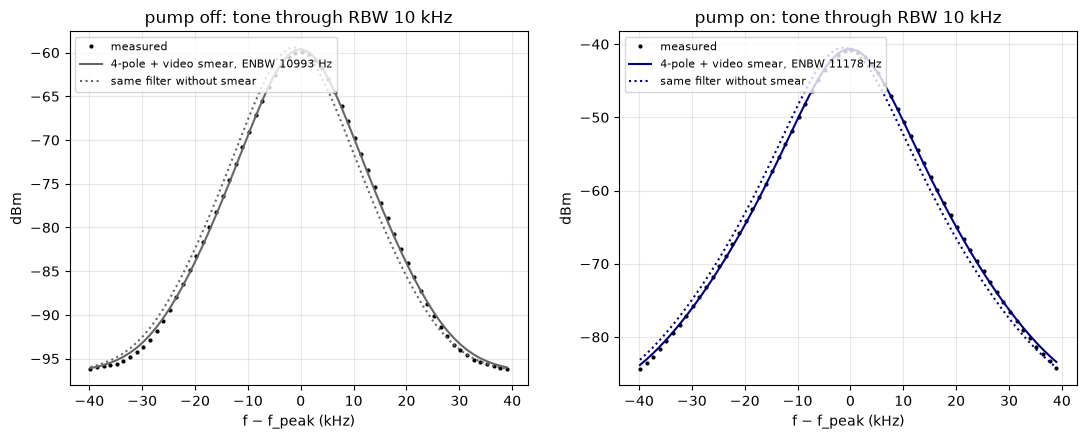

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for k, (name, f, y, r, e, c) in enumerate((("pump off", f_off, y_off, r_off, e_off, "0.4"),
                                            ("pump on", f_on, y_on, r_on, e_on, "navy"))):
    x = (f - r["f_pk"]) / 1e3
    m = np.abs(f - r["f_pk"]) < 40e3
    model = swept_model(f, e["peak_true"], e["f0"], e["a"], r["floor_w"], e["smear"])
    unsmeared = 10 * np.log10((10 ** (e["peak_true"] / 10) * 1e-3 * (1 + ((f - e["f0"]) / e["a"]) ** 2) ** -4
                               + r["floor_w"]) * 1e3)
    ax[k].plot(x[m], y[m], "k.", ms=4, label="measured")
    ax[k].plot(x[m], model[m], color=c, label=f"4-pole + video smear, ENBW {e['fit']:.0f} Hz")
    ax[k].plot(x[m], unsmeared[m], color=c, ls=":", label="same filter without smear")
    ax[k].set(xlabel="f − f_peak (kHz)", ylabel="dBm", title=f"{name}: tone through RBW 10 kHz")
    ax[k].grid(alpha=0.3)
    ax[k].legend(fontsize=8, loc="upper left")
plt.show()

## System noise temperature
At the qubit plane, then moved past the optional losses (all three planes coincide when both losses are 0 dB).
Values are printed as nominal [min, max] over the uncertainties set in the parameters.

In [25]:
import itertools

f_sig = d_on["instruments"]["rf_synth"]["probe_frequency_hz"]
T_q = h * f_sig / kB                                  # one photon, hf/k_B (SQL of T_sys)
n_th = lambda T: 0.5 / np.tanh(h * f_sig / (2 * kB * T))
c_log = 10 ** (LOG_VBW_CORR_DB / 10)
t_sys = lambda floor_w, gain: floor_w * c_log / (kB * ENBW * gain)
PLANE_LABELS = {"qubit": "qubit plane", "twpa": "TWPA input", "amp": "TWPA gain medium"}

def noise_budget(g_off_db, dg_db, l1_db, lt_db):
    # every derived number for one set of gain and loss inputs (dB)
    g_off, g_twpa = 10 ** (g_off_db / 10), 10 ** (dg_db / 10)
    T_off_q = t_sys(r_off["floor_w"], g_off)
    T_on_q = t_sys(r_on["floor_w"], g_off * g_twpa)
    a1, aT = 10 ** (-l1_db / 10), 10 ** (-lt_db / 10)
    n_in_q = n_th(T_IN_K)
    n_in_t = a1 * n_in_q + (1 - a1) * n_th(T_LOSS_K)
    n_in_a = aT * n_in_t + (1 - aT) * n_th(T_LOSS_K)
    b = {}
    for key, alpha, n_in in (("qubit", 1.0, n_in_q), ("twpa", a1, n_in_t), ("amp", a1 * aT, n_in_a)):
        n_off, n_on = alpha * T_off_q / T_q, alpha * T_on_q / T_q
        b[key] = {"alpha": alpha, "n_in": n_in, "T_off": alpha * T_off_q, "T_on": alpha * T_on_q,
                  "n_sys_off": n_off, "n_sys_on": n_on, "n_add_on": n_on - n_in}
    a = b["amp"]
    b["n_post"] = (a["n_sys_off"] - a["n_in"]) / g_twpa    # chain after the TWPA, referred to its gain medium
    b["n_twpa"] = a["n_sys_on"] - a["n_in"] - b["n_post"]   # TWPA intrinsic added noise, Eq. (G.6)
    b["n_twpa_sql"] = 0.5 * (1 - 1 / g_twpa)                # Caves limit for gain g_twpa
    b["eta"] = 1 / (2 * b["qubit"]["n_sys_on"])
    b["G_on_db"] = g_off_db + dg_db
    b["net_gain_db"] = dg_db - lt_db
    return b

# nominal inputs and every combination of (-u, 0, +u)
nominal = (G_OFF_DB, dB(dG), LOSS_QUBIT_TWPA_DB, LOSS_TWPA_DB)
unc = (G_OFF_UNC_DB, DG_UNC_DB, LOSS_QUBIT_TWPA_UNC_DB, LOSS_TWPA_UNC_DB)
combos = set()
for s in itertools.product((-1, 0, 1), repeat=4):
    p = [v + k * u for v, k, u in zip(nominal, s, unc)]
    p[2], p[3] = max(p[2], 0.0), max(p[3], 0.0)          # a loss is never negative
    combos.add(tuple(p))
nom = noise_budget(*nominal)
cases = [noise_budget(*p) for p in combos]

def rng(get):
    v = [get(c) for c in cases]
    return get(nom), min(v), max(v)

def fmt(get, digits=3):
    c, lo, hi = rng(get)
    return f"{c:.{digits}f} [{lo:.{digits}f}, {hi:.{digits}f}]"

print(f"ENBW {ENBW:.0f} Hz, hf/k_B = {T_q*1e3:.1f} mK, {len(cases)} input combinations")
print(f"G_off {G_OFF_DB:.2f} ± {G_OFF_UNC_DB:g} dB, ΔG {dB(dG):.2f} ± {DG_UNC_DB:g} dB, "
      f"loss qubit -> TWPA {LOSS_QUBIT_TWPA_DB:g} ± {LOSS_QUBIT_TWPA_UNC_DB:g} dB, "
      f"TWPA loss {LOSS_TWPA_DB:g} ± {LOSS_TWPA_UNC_DB:g} dB (at {T_LOSS_K*1e3:g} mK)")
print(f"G_on {fmt(lambda b: b['G_on_db'], 2)} dB, net TWPA gain {fmt(lambda b: b['net_gain_db'], 2)} dB\n")

rows = [("T_sys,off (K)", "T_off"), ("T_sys,on (K)", "T_on"), ("n_sys,on", "n_sys_on"), ("n_add,on", "n_add_on")]
print(f"{'':14s}" + "".join(f"{PLANE_LABELS[k]:>26s}" for k in PLANE_LABELS))
for name, q in rows:
    print(f"{name:14s}" + "".join(f"{fmt(lambda b: b[k][q]):>26s}" for k in PLANE_LABELS))
print(f"{'n_in':14s}" + "".join(f"{nom[k]['n_in']:>26.3f}" for k in PLANE_LABELS))

print(f"\nquantum efficiency at the qubit η = 1/(2 n_sys,on) = {fmt(lambda b: b['eta'])}")
print("\nFriis split at the TWPA gain medium, pump on:")
print(f"  TWPA intrinsic added  {fmt(lambda b: b['n_twpa'])} photons  (SQL ½(1 − 1/G) = {nom['n_twpa_sql']:.3f})")
print(f"  chain after the TWPA  {fmt(lambda b: b['n_post'])} photons")
_, lo, hi = rng(lambda b: b["n_twpa"] - b["n_twpa_sql"])
if hi < 0:
    print("  NOTE: below the quantum limit over the whole range -> the T_sys scale or the loss model is off")
elif lo < 0:
    print("  part of the range lies below the quantum limit")

ENBW 11086 Hz, hf/k_B = 267.6 mK, 3 input combinations
G_off 53.72 ± 0.5 dB, ΔG 19.09 ± 0 dB, loss qubit -> TWPA 0 ± 0 dB, TWPA loss 0 ± 0 dB (at 20 mK)
G_on 72.80 [72.30, 73.30] dB, net TWPA gain 19.09 [19.09, 19.09] dB

                             qubit plane                TWPA input          TWPA gain medium
T_sys,off (K)     10.478 [9.338, 11.756]    10.478 [9.338, 11.756]    10.478 [9.338, 11.756]
T_sys,on (K)        0.675 [0.601, 0.757]      0.675 [0.601, 0.757]      0.675 [0.601, 0.757]
n_sys,on            2.522 [2.247, 2.829]      2.522 [2.247, 2.829]      2.522 [2.247, 2.829]
n_add,on            2.022 [1.747, 2.329]      2.022 [1.747, 2.329]      2.022 [1.747, 2.329]
n_in                               0.500                     0.500                     0.500

quantum efficiency at the qubit η = 1/(2 n_sys,on) = 0.198 [0.177, 0.222]

Friis split at the TWPA gain medium, pump on:
  TWPA intrinsic added  1.545 [1.323, 1.793] photons  (SQL ½(1 − 1/G) = 0.494)
  chain after the T

## Noise spectra in temperature and photon units

Each SA point converted to $T(f) = \alpha\,P_\mathrm{read}(f)\,10^{c/10} / (k_B B_N G)$ at the plane chosen by
`PLOT_PLANE`, with $G_\mathrm{off}$ for the pump-off trace and $G_\mathrm{on}$ for the pump-on trace. Away from
the tone this is $T_\mathrm{sys}$; the peak is the probe tone itself, not noise. Right: the same data as system
added noise $n_\mathrm{add} = k_B T/hf - n_\mathrm{in}$. Shaded: range over the uncertainties. The SQL is
$T = hf/k_B$, i.e. $n_\mathrm{add}$ = ½.

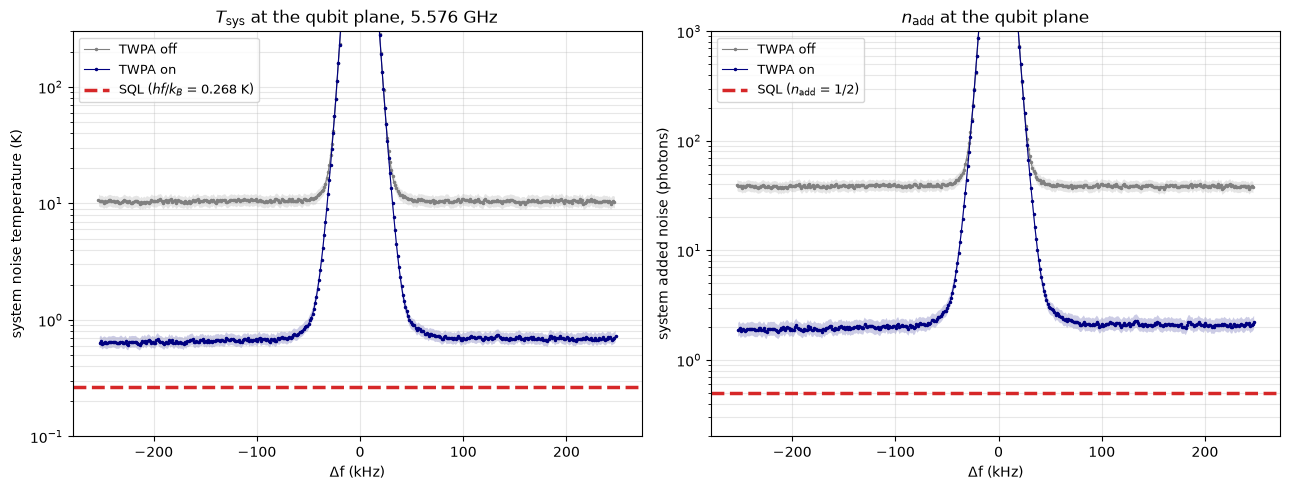

In [26]:
label = PLANE_LABELS[PLOT_PLANE]

def spectra(b):
    # each trace scaled so that its floor reads the T_sys of this case
    p = b[PLOT_PLANE]
    T_off_s = r_off["P"] * p["T_off"] / r_off["floor_w"]
    T_on_s = r_on["P"] * p["T_on"] / r_on["floor_w"]
    return np.array([T_off_s, T_on_s, T_off_s / T_q - p["n_in"], T_on_s / T_q - p["n_in"]])

spec_nom = spectra(nom)
spec_all = np.array([spectra(c) for c in cases])
spec_lo, spec_hi = spec_all.min(axis=0), spec_all.max(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, (name, f, r, c) in enumerate((("TWPA off", f_off, r_off, "0.5"), ("TWPA on", f_on, r_on, "navy"))):
    x = (f - r["f_pk"]) / 1e3
    for k in range(2):
        j = i + 2 * k
        ax[k].fill_between(x, spec_lo[j], spec_hi[j], color=c, alpha=0.2, lw=0)
        ax[k].plot(x, spec_nom[j], ".-", color=c, ms=3, lw=0.8, label=name)
ax[0].axhline(T_q, color="C3", ls="--", lw=2.5, label=f"SQL ($hf/k_B$ = {T_q:.3f} K)")
ax[1].axhline(0.5, color="C3", ls="--", lw=2.5, label="SQL ($n_\\mathrm{add}$ = 1/2)")
ax[0].set(ylabel="system noise temperature (K)", title=f"$T_\\mathrm{{sys}}$ at the {label}, {f_sig/1e9:g} GHz")
ax[1].set(ylabel="system added noise (photons)", title=f"$n_\\mathrm{{add}}$ at the {label}")
for a in ax:
    a.set_yscale("log")
    a.set_xlabel("Δf (kHz)")
    a.grid(alpha=0.3, which="both")
    a.legend(loc="upper left", fontsize=9)
ax[0].set_ylim(0.1, 300)
ax[1].set_ylim(0.2, 1000)
plt.tight_layout()
plt.show()